# Week 4 – LangChain, LangGraph & AI Agents
**Skill Set Go EduTech AI/ML Internship**

All four tasks are included in this Colab notebook:
- 4.1 RAG application with LangChain + FAISS
- 4.2 Multi-step workflow with LangGraph
- 4.3 Observability: measured latency, source checks, and failure cases; optional LangSmith tracing
- 4.4 Capstone AI Agent combining RAG, calculator tool, LangGraph, and Gradio demo

Run every cell from top to bottom. Record only actual runtime results; do not invent metrics.

In [1]:
!pip -q install -U langchain-core langchain-community langchain-text-splitters langgraph faiss-cpu sentence-transformers gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 573.3/573.3 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 18.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 259.6/259.6 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 16.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 740.6/740.6 kB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.4/31.4 MB 18.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.5/64.5 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 18.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 368.4 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.4/162.4 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 2.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently 

In [2]:
import os, time, operator, ast, math
from typing import TypedDict, List
import pandas as pd
import matplotlib.pyplot as plt
from langchain_core.documents import Document
from langchain_community.embeddings import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langgraph.graph import StateGraph, END
print("Setup complete.")

/tmp/ipykernel_877/1675171349.py:6: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.embeddings import HuggingFaceEmbeddings


Setup complete.


## 4.1 — RAG Application (LangChain + FAISS)

In [3]:
knowledge_items = [
("internship_submission_guide.txt","Keep the GitHub repository organized by week. Each project folder should include a README with objective, tools, approach, results, and future improvements. Test links in a private browser before submission."),
("week4_roadmap.txt","Week 4 covers a retrieval-augmented generation application using LangChain and FAISS or Chroma, a multi-step workflow in LangGraph, LLM observability using LangSmith, and an AI Agent capstone combining RAG, tool use, and multi-step reasoning."),
("project_report_guide.txt","A technical report should describe the problem, objectives, architecture, tools, implementation, evaluation, limitations, and future improvements. Report only metrics measured during actual experiments."),
("student_support_faq.txt","If a question is not answered by available documents, say the knowledge base does not contain enough information and suggest checking the official source. Do not invent deadlines, policies, or contact details."),
("privacy_security.txt","Never put passwords, API keys, access tokens, private student records, or confidential information in a public repository. Use environment variables or secret managers for credentials."),
("agent_tools.txt","An AI agent can combine retrieval with tools. A calculator is suitable for arithmetic. Use tools only when relevant, check tool output, and explain when evidence is insufficient.")
]
documents=[Document(page_content=t,metadata={"source":s}) for s,t in knowledge_items]
chunks=RecursiveCharacterTextSplitter(chunk_size=350,chunk_overlap=40).split_documents(documents)
print("Documents:",len(documents),"Chunks:",len(chunks))
display(pd.DataFrame([{"source":d.metadata["source"],"preview":d.page_content[:100]} for d in chunks]))

Documents: 6 Chunks: 6


,source,preview
0,internship_submission_guide.txt,Keep the GitHub repository organized by week. ...
1,week4_roadmap.txt,Week 4 covers a retrieval-augmented generation...
2,project_report_guide.txt,A technical report should describe the problem...
3,student_support_faq.txt,If a question is not answered by available doc...
4,privacy_security.txt,"Never put passwords, API keys, access tokens, ..."
5,agent_tools.txt,An AI agent can combine retrieval with tools. ...


In [4]:
embeddings=HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2",
    model_kwargs={"device":"cpu"},encode_kwargs={"normalize_embeddings":True})
vector_store=FAISS.from_documents(chunks,embeddings)
retriever=vector_store.as_retriever(search_kwargs={"k":3})
print("FAISS vector index created.")

/tmp/ipykernel_877/918202543.py:1: LangChainDeprecationWarning: The class `HuggingFaceEmbeddings` was deprecated in LangChain 0.2.2 and will be removed in 1.0. An updated version of the class exists in the `langchain-huggingface package and should be used instead. To use it run `pip install -U `langchain-huggingface` and import as `from `langchain_huggingface import HuggingFaceEmbeddings``.
  embeddings=HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2",


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

FAISS vector index created.


In [5]:
def rag_answer(question):
    start=time.perf_counter()
    docs=retriever.invoke(question)
    latency=(time.perf_counter()-start)*1000
    if not docs:
        return {"question":question,"answer":"The knowledge base does not contain enough information. Please check the official source.","sources":[],"latency_ms":round(latency,2)}
    answer="Based on retrieved knowledge-base passages:\n"+"\n".join(
        f"- {d.page_content} [Source: {d.metadata.get('source','unknown')}]" for d in docs
    )+"\n\nVerify important details against the official source."
    return {"question":question,"answer":answer,"sources":list(dict.fromkeys(d.metadata.get("source","unknown") for d in docs)),"latency_ms":round(latency,2)}
result=rag_answer("What should a project README contain?")
print(result["answer"]); print("Sources:",result["sources"],"| latency ms:",result["latency_ms"])

Based on retrieved knowledge-base passages:
- Keep the GitHub repository organized by week. Each project folder should include a README with objective, tools, approach, results, and future improvements. Test links in a private browser before submission. [Source: internship_submission_guide.txt]
- Never put passwords, API keys, access tokens, private student records, or confidential information in a public repository. Use environment variables or secret managers for credentials. [Source: privacy_security.txt]
- A technical report should describe the problem, objectives, architecture, tools, implementation, evaluation, limitations, and future improvements. Report only metrics measured during actual experiments. [Source: project_report_guide.txt]

Verify important details against the official source.
Sources: ['internship_submission_guide.txt', 'privacy_security.txt', 'project_report_guide.txt'] | latency ms: 24.31


**RAG implementation note:** the default answer assembly is grounded and extractive so the notebook works without a paid LLM API. It demonstrates retrieval and source grounding.

## 4.2 — Multi-Step Workflow with LangGraph

In [6]:
class AgentState(TypedDict):
    question: str
    retrieved: List[dict]
    answer: str
    sources: List[str]
    supported: bool
    latency_ms: float

def retrieve_node(state: AgentState):
    start=time.perf_counter(); docs=retriever.invoke(state["question"])
    return {"retrieved":[{"text":d.page_content,"source":d.metadata.get("source","unknown")} for d in docs],
            "sources":list(dict.fromkeys(d.metadata.get("source","unknown") for d in docs)),
            "latency_ms":round((time.perf_counter()-start)*1000,2)}

def draft_node(state: AgentState):
    docs=state.get("retrieved",[])
    if not docs: return {"answer":"The knowledge base does not contain enough information. Please check the official source.","supported":False}
    return {"answer":"Based on retrieved documents:\n"+"\n".join(f"- {d['text']} [Source: {d['source']}]" for d in docs),"supported":True}

def quality_node(state: AgentState):
    if not state.get("answer","").strip() or not state.get("sources",[]):
        return {"answer":"I could not verify an answer from the current knowledge base. Please check the official source.","supported":False}
    return {"supported":True}

builder=StateGraph(AgentState)
builder.add_node("retrieve",retrieve_node); builder.add_node("draft",draft_node); builder.add_node("quality_check",quality_node)
builder.set_entry_point("retrieve"); builder.add_edge("retrieve","draft"); builder.add_edge("draft","quality_check"); builder.add_edge("quality_check",END)
agent_graph=builder.compile()
workflow_result=agent_graph.invoke({"question":"What are the main Week 4 components?","retrieved":[],"answer":"","sources":[],"supported":False,"latency_ms":0.0})
print(workflow_result["answer"]); print("Sources:",workflow_result["sources"]); print("Supported:",workflow_result["supported"])

Based on retrieved documents:
- Keep the GitHub repository organized by week. Each project folder should include a README with objective, tools, approach, results, and future improvements. Test links in a private browser before submission. [Source: internship_submission_guide.txt]
- Week 4 covers a retrieval-augmented generation application using LangChain and FAISS or Chroma, a multi-step workflow in LangGraph, LLM observability using LangSmith, and an AI Agent capstone combining RAG, tool use, and multi-step reasoning. [Source: week4_roadmap.txt]
- A technical report should describe the problem, objectives, architecture, tools, implementation, evaluation, limitations, and future improvements. Report only metrics measured during actual experiments. [Source: project_report_guide.txt]
Sources: ['internship_submission_guide.txt', 'week4_roadmap.txt', 'project_report_guide.txt']
Supported: True


### LangGraph workflow diagram

```text
Question → Retrieve from FAISS → Draft grounded answer → Check evidence → Return answer + sources
```

## 4.3 — Observability and Evaluation

,question,expected_source,retrieved_sources,source_check_pass,latency_ms,answer_preview
0,What should a README contain?,internship_submission_guide.txt,"privacy_security.txt, week4_roadmap.txt, inter...",True,16.89,Based on retrieved knowledge-base passages: - ...
1,Which tools are covered in Week 4?,week4_roadmap.txt,"week4_roadmap.txt, internship_submission_guide...",True,15.14,Based on retrieved knowledge-base passages: - ...
2,How should API keys be handled?,privacy_security.txt,"privacy_security.txt, week4_roadmap.txt, inter...",True,15.35,Based on retrieved knowledge-base passages: - ...
3,What if the knowledge base does not answer?,student_support_faq.txt,"student_support_faq.txt, agent_tools.txt, priv...",True,16.13,Based on retrieved knowledge-base passages: - ...
4,What is the private phone number of the coordi...,No source expected,"privacy_security.txt, student_support_faq.txt,...",False,16.13,Based on retrieved knowledge-base passages: - ...


Mean retrieval latency (ms): 15.93
Source check pass rate (%): 80.0


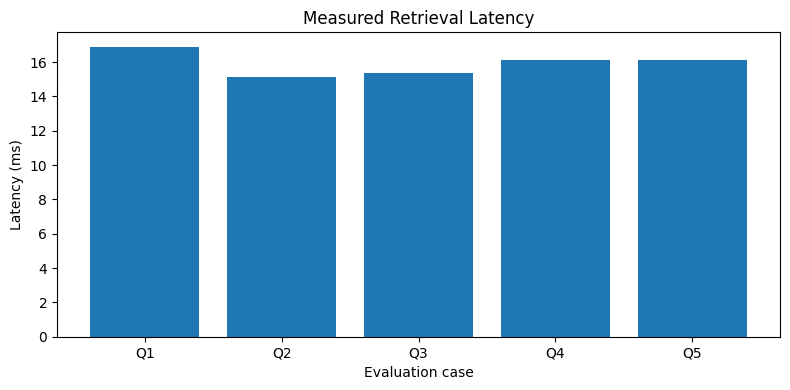

In [7]:
evaluation_cases=[
 {"question":"What should a README contain?","expected_source":"internship_submission_guide.txt"},
 {"question":"Which tools are covered in Week 4?","expected_source":"week4_roadmap.txt"},
 {"question":"How should API keys be handled?","expected_source":"privacy_security.txt"},
 {"question":"What if the knowledge base does not answer?","expected_source":"student_support_faq.txt"},
 {"question":"What is the private phone number of the coordinator?","expected_source":None}
]
rows=[]
for case in evaluation_cases:
    r=rag_answer(case["question"])
    hit=(case["expected_source"] in r["sources"]) if case["expected_source"] else len(r["sources"])==0
    rows.append({"question":case["question"],"expected_source":case["expected_source"] or "No source expected",
        "retrieved_sources":", ".join(r["sources"]),"source_check_pass":hit,"latency_ms":r["latency_ms"],
        "answer_preview":r["answer"][:140].replace("\n"," ")})
evaluation_df=pd.DataFrame(rows); display(evaluation_df)
print("Mean retrieval latency (ms):",round(evaluation_df["latency_ms"].mean(),2))
print("Source check pass rate (%):",round(evaluation_df["source_check_pass"].mean()*100,2))
evaluation_df.to_csv("week4_observability_evaluation.csv",index=False)
plt.figure(figsize=(8,4)); plt.bar(range(len(evaluation_df)),evaluation_df["latency_ms"])
plt.xticks(range(len(evaluation_df)),[f"Q{i+1}" for i in range(len(evaluation_df))])
plt.xlabel("Evaluation case"); plt.ylabel("Latency (ms)"); plt.title("Measured Retrieval Latency"); plt.tight_layout(); plt.show()

In [8]:
ENABLE_LANGSMITH=False
if ENABLE_LANGSMITH:
    from getpass import getpass
    os.environ["LANGCHAIN_TRACING_V2"]="true"
    os.environ["LANGCHAIN_PROJECT"]="Week4-Campus-Knowledge-AI-Agent"
    if not os.environ.get("LANGCHAIN_API_KEY"):
        os.environ["LANGCHAIN_API_KEY"]=getpass("LangSmith API key (hidden): ")
    print("Tracing environment configured; verify traces in your LangSmith account.")
else:
    print("Remote tracing disabled. Local latency/source evaluation is recorded above.")

Remote tracing disabled. Local latency/source evaluation is recorded above.


## 4.4 — Capstone AI Agent: RAG + Tool Use + LangGraph

In [9]:
# Safe calculator using AST parsing, not eval().
_ALLOWED_BINOPS={ast.Add:operator.add,ast.Sub:operator.sub,ast.Mult:operator.mul,ast.Div:operator.truediv,ast.Pow:operator.pow,ast.Mod:operator.mod}
_ALLOWED_UNARYOPS={ast.UAdd:operator.pos,ast.USub:operator.neg}
def safe_calculate(expression):
    def ev(node):
        if isinstance(node,ast.Constant) and isinstance(node.value,(int,float)): return node.value
        if isinstance(node,ast.BinOp) and type(node.op) in _ALLOWED_BINOPS:
            a,b=ev(node.left),ev(node.right)
            if isinstance(node.op,ast.Pow) and abs(b)>8: raise ValueError("Exponent too large")
            return _ALLOWED_BINOPS[type(node.op)](a,b)
        if isinstance(node,ast.UnaryOp) and type(node.op) in _ALLOWED_UNARYOPS: return _ALLOWED_UNARYOPS[type(node.op)](ev(node.operand))
        raise ValueError("Only basic arithmetic is allowed")
    try:
        value=ev(ast.parse(expression,mode="eval").body)
        if not math.isfinite(float(value)): raise ValueError("Non-finite result")
        return {"ok":True,"result":value}
    except Exception as e: return {"ok":False,"error":str(e)}

def campus_agent(question):
    question=(question or "").strip()
    if not question: return {"answer":"Please enter a question.","sources":[],"tool":"none","latency_ms":0}
    start=time.perf_counter(); candidate=question
    for prefix in ["calculate:","compute:"]:
        if question.lower().startswith(prefix): candidate=question[len(prefix):].strip().rstrip("?")
    if any(c.isdigit() for c in candidate) and any(op in candidate for op in ["+","-","*","/","%"]) and all(c in "0123456789.+-*/%() \t" for c in candidate):
        r=safe_calculate(candidate)
        answer=f"Calculator result: {r['result']}" if r["ok"] else f"Calculation error: {r['error']}"
        return {"answer":answer,"sources":[],"tool":"calculator","latency_ms":round((time.perf_counter()-start)*1000,2)}
    r=agent_graph.invoke({"question":question,"retrieved":[],"answer":"","sources":[],"supported":False,"latency_ms":0.0})
    return {"answer":r["answer"],"sources":r.get("sources",[]),"tool":"FAISS RAG + LangGraph","latency_ms":round((time.perf_counter()-start)*1000,2),"supported":r.get("supported",False)}

print(campus_agent("What should a project README contain?"))
print(campus_agent("Calculate: 1200 / 8"))

{'answer': 'Based on retrieved documents:\n- Keep the GitHub repository organized by week. Each project folder should include a README with objective, tools, approach, results, and future improvements. Test links in a private browser before submission. [Source: internship_submission_guide.txt]\n- Never put passwords, API keys, access tokens, private student records, or confidential information in a public repository. Use environment variables or secret managers for credentials. [Source: privacy_security.txt]\n- A technical report should describe the problem, objectives, architecture, tools, implementation, evaluation, limitations, and future improvements. Report only metrics measured during actual experiments. [Source: project_report_guide.txt]', 'sources': ['internship_submission_guide.txt', 'privacy_security.txt', 'project_report_guide.txt'], 'tool': 'FAISS RAG + LangGraph', 'latency_ms': 21.03, 'supported': True}
{'answer': 'Calculator result: 150.0', 'sources': [], 'tool': 'calcula

In [10]:
import gradio as gr
def chat_fn(message, history):
    r=campus_agent(message); sources=", ".join(r.get("sources",[])) or "No document source (calculator/fallback)"
    return r["answer"]+f"\n\nTool: {r.get('tool')}\nSources: {sources}\nLatency: {r.get('latency_ms')} ms"
demo=gr.ChatInterface(fn=chat_fn,title="Campus Knowledge AI Agent",
    description="Ask about the sample knowledge base or try: Calculate: 1200 / 8")
print("App created. Run next cell to launch a temporary demo link.")

App created. Run next cell to launch a temporary demo link.


In [11]:
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://70fff96627b12fd7ad.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Architecture, limitations and improvements

**Architecture:** question → router → calculator tool or FAISS retrieval → LangGraph retrieve/draft/quality check → response with sources → Gradio UI.

**Limitations:** small sample knowledge base; extractive answer assembly rather than LLM synthesis; retrieval depends on documents/embeddings; LangSmith remote traces require an account/key; Gradio share link is temporary.

**Improvements:** ingest permitted PDFs with page metadata, connect an approved LLM, add human-rated evaluation, persist the index, deploy to managed hosting, and add authentication before using private documents.

## Final Week 4 checklist
- [ ] 4.1 RAG + FAISS retrieval and architecture notes
- [ ] 4.2 LangGraph workflow, code and diagram
- [ ] 4.3 evaluation table, latency measurements, failure case, LangSmith trace screenshots if enabled
- [ ] 4.4 integrated agent, calculator tool, and working Gradio demo